<a href="https://colab.research.google.com/github/FaizMi16/ProyekAkhir_5A_LaptopPrice/blob/main/03_varian2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Load Data & Preprocessing Dasar

In [ ]:
# 1. Install library kaggle (biasanya sudah ada di Colab, tapi untuk memastikan)
!pip install -q kaggle

In [ ]:
# 2. Mengatur Environment Variable untuk API Token
import os
import getpass

print("Silakan tempel (paste) API Token Kaggle Anda (dimulai dengan KGAT_...) dan tekan Enter:")
# getpass digunakan agar token yang Anda ketik tidak terlihat di layar
kaggle_token = getpass.getpass('KAGGLE_API_TOKEN: ')

# Menyetel environment variable agar library kaggle bisa membacanya
os.environ['KAGGLE_API_TOKEN'] = kaggle_token

print("\nOtentikasi API Kaggle Selesai!")

Silakan tempel (paste) API Token Kaggle Anda (dimulai dengan KGAT_...) dan tekan Enter:
KAGGLE_API_TOKEN: ··········

Otentikasi API Kaggle Selesai!


In [ ]:
# ---------------------------------------------------------
# 3. MENGUNDUH DATASET CONTOH
# Perintah: kaggle datasets download -d [nama-pemilik/nama-dataset]
# ---------------------------------------------------------
print("Mengunduh dataset Life Expectancy...")
!kaggle datasets download -d muhammetvarl/laptop-price

Mengunduh dataset Life Expectancy...
Dataset URL: https://www.kaggle.com/datasets/muhammetvarl/laptop-price
License(s): other
100% 28.0k/28.0k [00:00<00:00, 45.3MB/s]



In [ ]:
# 4. Mengekstrak file ZIP hasil unduhan
# -q artinya 'quiet' (tanpa log ekstraksi yang panjang)
!unzip -q laptop-price.zip -d dataset_laptop/

print("Unduhan dan Ekstraksi Selesai!")

Unduhan dan Ekstraksi Selesai!


In [ ]:
# ---------------------------------------------------------
# 5. MEMUAT DATA KE PANDAS (Langkah Awal EDA)
# ---------------------------------------------------------
import pandas as pd

# Membaca file CSV yang sudah diekstrak dengan encoding latin-1
df = pd.read_csv('dataset_laptop/laptop_price.csv', encoding='latin-1')

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df.columns = df.columns.str.strip() # Rapikan nama kolom

# --- Preprocessing ---
# Bersihkan RAM
df['Ram_GB'] = pd.to_numeric(df['Ram'].astype(str).str.replace('GB', '', regex=False).str.strip(), errors='coerce')
df['Ram_GB'] = df['Ram_GB'].fillna(df['Ram_GB'].median()).astype(int)

# Bersihkan Berat
df['Weight_kg'] = pd.to_numeric(df['Weight'].astype(str).str.replace('kg', '', regex=False).str.strip(), errors='coerce')
df['Weight_kg'] = df['Weight_kg'].fillna(df['Weight_kg'].median())

# Bersihkan Memory
def parse_memory(mem):
    mem = str(mem)
    total_gb = 0.0
    for val, unit in re.findall(r'(\d+\.?\d*)\s*(GB|TB)', mem):
        v = float(val)
        total_gb += v * 1024 if unit == 'TB' else v
    return total_gb
df['Storage_GB'] = df['Memory'].apply(parse_memory)

print("Data berhasil dibersihkan. Shape:", df.shape)

Data berhasil dibersihkan. Shape: (1303, 16)


 (Metode Elbow)

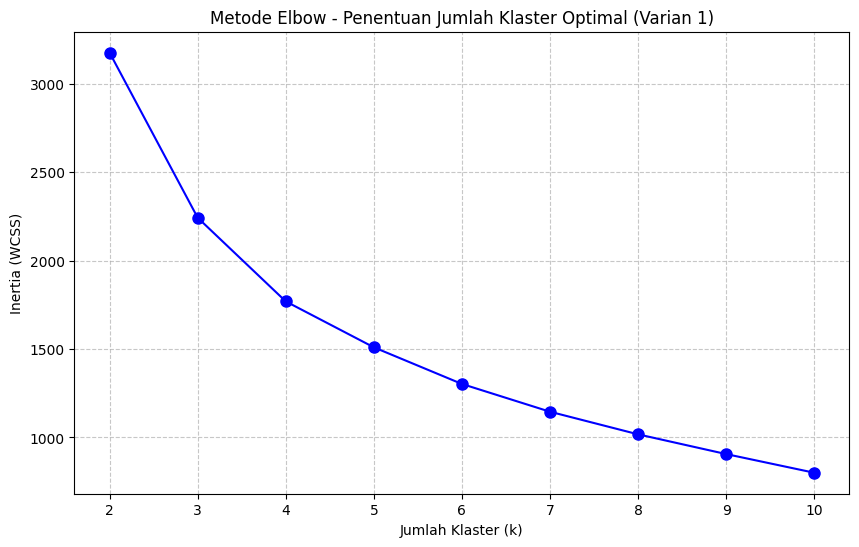

In [ ]:
# Pilih fitur untuk segmentasi
fitur = ['Ram_GB', 'Inches', 'Weight_kg', 'Storage_GB']
X = df[fitur]

# Scaling (Wajib!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Looping Metode Elbow (k=2 sampai 10)
inertia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot Grafik
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b', markersize=8)
plt.title('Metode Elbow - Penentuan Jumlah Klaster Optimal (Varian 1)')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Berdasarkan grafik Metode Elbow di atas, penurunan Inertia paling drastis terjadi hingga k=4. Setelah k=4, garis mulai melandai. Oleh karena itu, jumlah klaster optimal untuk segmentasi laptop ini ditetapkan pada k = 4.

# **varian 2 (penentuan K)**


K = 2, Silhouette Score = 0.3837
K = 3, Silhouette Score = 0.3940
K = 4, Silhouette Score = 0.3973
K = 5, Silhouette Score = 0.4264
K = 6, Silhouette Score = 0.4369
K = 7, Silhouette Score = 0.4448
K = 8, Silhouette Score = 0.4521
K = 9, Silhouette Score = 0.4637
K = 10, Silhouette Score = 0.4453


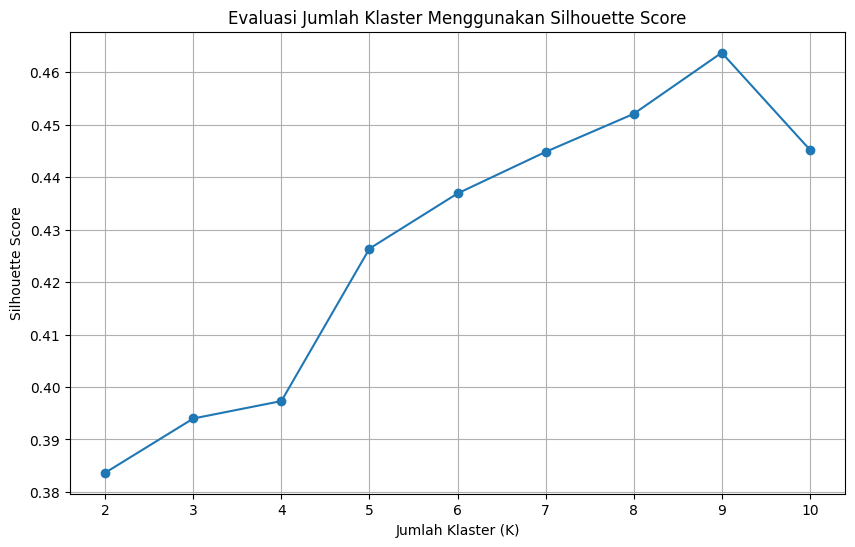

K terbaik berdasarkan Silhouette Score: 9
Silhouette Score tertinggi: 0.4637


In [ ]:

from sklearn.metrics import silhouette_score

# Evaluasi Silhouette Score untuk beberapa nilai K
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Visualisasi Silhouette Score
plt.figure(figsize=(10, 6))
plt.plot(K_range, silhouette_scores, marker='o')
plt.title('Evaluasi Jumlah Klaster Menggunakan Silhouette Score')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Silhouette Score')
plt.xticks(K_range)
plt.grid(True)
plt.show()

# Menentukan K terbaik
best_k = list(K_range)[np.argmax(silhouette_scores)]
best_score = max(silhouette_scores)

print(f"K terbaik berdasarkan Silhouette Score: {best_k}")
print(f"Silhouette Score tertinggi: {best_score:.4f}")


### Analisis Perbedaan Hasil K (Elbow vs. Silhouette Score)

Perbedaan penentuan jumlah klaster optimal antara Metode Elbow ($K=4$) dan Silhouette Score ($K=9$) terjadi karena kedua metode mengukur karakteristik struktur data yang berbeda. Metode Elbow berfokus pada minimalisasi variasi internal klaster (*Inertia* atau WCSS), yang cenderung terus menurun seiring bertambahnya jumlah klaster sehingga titik 'siku' ($K=4$) dipilih sebagai titik efisiensi optimum sebelum penurunan melandai. Sebaliknya, Silhouette Score mengukur tidak hanya seberapa dekat suatu poin dengan klasternya sendiri (*cohesion*), melainkan juga seberapa jauh jaraknya dari klaster tetangga terdekat (*separation*). Silhouette Score yang mencapai puncak pada $K=9$ menunjukkan bahwa pemisahan batas antar-kelompok lebih tegas dan definisi struktur klaster lebih optimal pada konfigurasi yang lebih spesifik tersebut, meskipun menghasilkan jumlah kelompok yang jauh lebih banyak.